# 02 - Explore the data

Steps 4 and 5 of the guide: load the curated dataset and look at how imbalanced the smell labels are.

In [1]:
import pandas as pd

path = "openpom/openpom/data/curated_datasets/curated_GS_LF_merged_4983.csv"
df = pd.read_csv(path)
print(df.shape)
df.head()

(4983, 140)


,nonStereoSMILES,descriptors,alcoholic,aldehydic,alliaceous,almond,amber,animal,anisic,apple,...,tropical,vanilla,vegetable,vetiver,violet,warm,waxy,weedy,winey,woody
0,CC(O)CN,fishy,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,CCC(=O)C(=O)O,fatty;lactonic;sweet;caramellic;creamy,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,O=C(O)CCc1ccccc1,rose;floral;fatty;sweet;musk;cinnamon;balsamic,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,OCc1ccc(O)cc1,medicinal;phenolic;fruity;nutty;bitter;sweet;a...,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,O=Cc1ccc(O)cc1,phenolic;woody;nutty;vanilla;hay;metallic;swee...,0,0,0,1,0,0,0,0,...,0,1,0,0,0,0,0,0,0,1


The frame has 4,983 rows: one SMILES column (`nonStereoSMILES`), a free-text `descriptors` column, and one 0/1 column per smell word (138 of them).

In [2]:
# count how often each smell word appears
counts = df.drop(columns=df.columns[:2]).sum().sort_values(ascending=False)
print("most common:")
print(counts.head(10))
print("\nrarest:")
print(counts.tail(10))

most common:
fruity    1902
green     1446
sweet     1429
floral    1100
herbal     756
woody      679
fatty      598
fresh      533
waxy       488
spicy      464
dtype: int64

rarest:
tomato          37
popcorn         36
sandalwood      36
gassy           35
clove           34
hawthorn        34
malty           33
orangeflower    33
bergamot        32
chamomile       31
dtype: int64


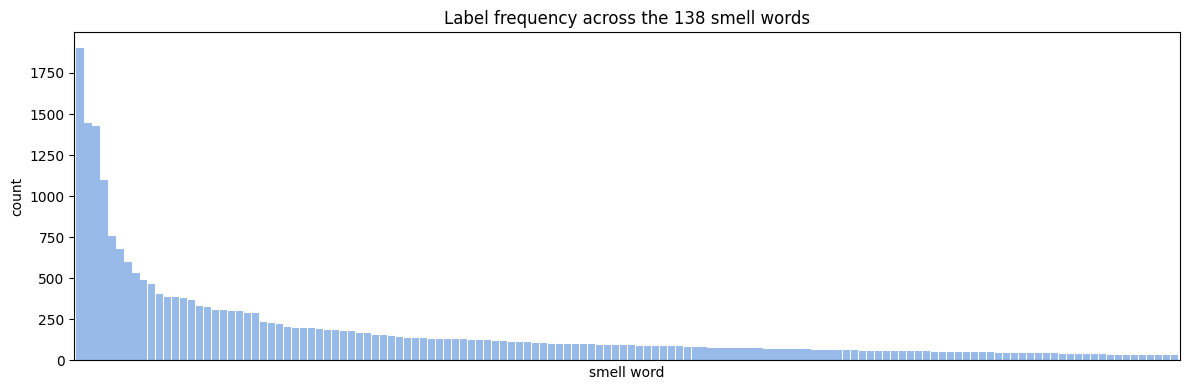

In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 4))
counts.plot(kind='bar', ax=ax, width=0.9, color='#97bae8')
ax.set_title('Label frequency across the 138 smell words')
ax.set_xlabel('smell word')
ax.set_ylabel('count')
ax.set_xticks([])
plt.tight_layout()
plt.show()

In [4]:
print("total labels set :", int(counts.sum()))
print("labels per row  :", round(counts.sum() / len(df), 2))
print("rows with 0 set :", int((df.drop(columns=df.columns[:2]).sum(axis=1) == 0).sum()))

total labels set : 24312
labels per row  : 4.88
rows with 0 set : 0
